In [1]:
import gc
import tempfile
import os.path
import pickle as pkl
import numpy as np
import random
from tqdm import tqdm
import json
import torch
import numpy as np
from sklearn import metrics
from sklearn.metrics import make_scorer
from sklearn.model_selection import KFold, cross_validate
from functools import partial
from utils import get_texts_for_ptype
from sklearn.model_selection import RepeatedKFold

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from filelock import FileLock
from torch.utils.data import random_split
from typing import Dict
from scipy.optimize import minimize_scalar

import torch_geometric.transforms as T
from torch_geometric.data import Data
from torch_geometric.nn import GATConv, SAGEConv, GCNConv
from torch_geometric.transforms import NormalizeFeatures
from torch_geometric.nn.aggr import PowerMeanAggregation, SoftmaxAggregation, SetTransformerAggregation, MLPAggregation, LSTMAggregation, SortAggregation, EquilibriumAggregation
from sklearn.utils.multiclass import unique_labels
from sklearn.feature_extraction.text import HashingVectorizer, TfidfVectorizer

from ray import train, tune

import datasets
from datasets import load_dataset, Dataset, load_metric

In [2]:
ptype2model = {
    'is_rct': 'BioBERT',
    'is_sr': 'PubMedBERT',
    'is_casecontrol': 'PubMedBERT',
    'is_cohort': 'PubMedBERT',
    'is_guideline': 'DistilBERT'
}

In [3]:
neg_pos_ratio_dict = {
    "is_rct": 5585042/489295,
    "is_sr": 5659292/121063,
    "is_casecontrol": 5628219/65790,
    "is_cohort": 5632460/78688,
    "is_guideline": 5676411/33826
}

def calc_precision(recall, specificity, neg_pos_ratio):
    return recall / (recall + neg_pos_ratio * (1 - specificity) + 1e-15)

def calc_f1(recall, precision):
    return 2*recall*precision/(recall+precision + 1e-15)

In [4]:
def predict(df, db=0):
    return [int(x>=db) for x in df ]

def get_scores(predictions):
    return [np.exp(p[1])/(np.exp(p[0]) + np.exp(p[1])) for p in predictions]

In [5]:
def load_data(data_dir="../data", ptype="is_rct"):
    model_name = ptype2model[ptype]
    x_tensor_path = os.path.join(data_dir, f"x_tensor_{model_name}_sample.pkl")
    with open(x_tensor_path, "rb") as f:
        x_tensor = pkl.load(f)
    
    pmid2node_id_path = os.path.join(data_dir, "pmid2node_id_sample.json")
    with open(pmid2node_id_path, "r") as f:
        pmid2node_id = json.load(f)
    
    PMIDS = os.path.join(data_dir, "pmids.pkl") 
    with open(PMIDS, 'rb') as f:
        pmids = pkl.load(f)
    
    edge_index_path = os.path.join(data_dir, "edge_index_sample.pkl")
    with open(edge_index_path, "rb") as f:
        edge_index = pkl.load(f)
    
    num_nodes = len(pmid2node_id)
    train_mask = [False for _ in range(num_nodes)]
    val_mask = [False for _ in range(num_nodes)]
    test_mask = [False for _ in range(num_nodes)]
        
    train_pmids = pmids[ptype]['pos']['train'] + pmids[ptype]['neg']['train']
    val_pmids = pmids[ptype]['pos']['val'] + pmids[ptype]['neg']['val']
    test_pmids = pmids[ptype]['pos']['test'] + pmids[ptype]['neg']['test']
        
    for pmid in train_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            train_mask[node_id] = True
        
    for pmid in val_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            val_mask[node_id] = True
                
    for pmid in test_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            test_mask[node_id] = True
        
    train_mask = torch.tensor(train_mask, dtype=torch.bool)
    val_mask = torch.tensor(val_mask, dtype=torch.bool)
    test_mask = torch.tensor(test_mask, dtype=torch.bool)
        
    y = [-1 for _ in range(num_nodes)]
    pos_pmids = pmids[ptype]['pos']['train'] + pmids[ptype]['pos']['val'] + pmids[ptype]['pos']['test']
    neg_pmids = pmids[ptype]['neg']['train'] + pmids[ptype]['neg']['val'] + pmids[ptype]['neg']['test']
        
    for pmid in pos_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            y[node_id] = 1
        
    for pmid in neg_pmids:
        if str(pmid) in pmid2node_id:
            node_id = pmid2node_id[str(pmid)]
            y[node_id] = 0
        
    y = torch.tensor(y, dtype=torch.long)
    edge_index = torch.tensor(edge_index)
    data = Data(x=torch.tensor(x_tensor, dtype=torch.float32), y=y, edge_index=edge_index, train_mask=train_mask, val_mask=val_mask, test_mask=test_mask)
    del y
    del x_tensor
    del edge_index
    del train_mask
    del val_mask
    del test_mask
    
    return data



class GAT(torch.nn.Module):
    def __init__(self, hid, in_head, out_head, dropout, num_classes = 2):
        super(GAT, self).__init__()
        self.hid = hid
        self.in_head = in_head
        self.out_head = out_head
        self.dropout = dropout
        
        
        self.conv1 = GATConv(768, self.hid, heads=self.in_head, dropout=self.dropout)
        self.conv2 = GATConv(self.hid*self.in_head, num_classes, concat=False,
                             heads=self.out_head, dropout=self.dropout)
#         self.conv = GATConv(data.num_features, num_classes, concat=True,
#                              heads=self.out_head, dropout=0.6)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
                
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        
        return F.log_softmax(x, dim=1)

class SAGENet(torch.nn.Module):
    def __init__(self, aggr="max", num_classes = 2):
        super(SAGENet, self).__init__()
        
        self.conv = SAGEConv(768,
                             num_classes,
#                              aggr=SumAggregation()
                             aggr=aggr) # max, mean, add ...)

    def forward(self, data):
        x = self.conv(data.x, data.edge_index)
        return F.log_softmax(x, dim=1)
    

class GCN(torch.nn.Module):
    def __init__(self, hidden_channels, dropout, num_classes = 2):
        super().__init__()
        torch.manual_seed(1234567)
        self.conv1 = GCNConv(768, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, num_classes)
        self.dropout = dropout

    def forward(self, data):
        x = self.conv1(data.x, data.edge_index)
        x = x.relu()
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, data.edge_index)
        return F.log_softmax(x, dim=1)

def train_helper(model, config, ptype):
    device = "cpu"
    if torch.cuda.is_available():
        device = "cuda:0"
        if torch.cuda.device_count() > 1:
            model = nn.DataParallel(model)
    model = model.to(device)
    model = model.train()

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"], weight_decay=5e-4)
#     optimizer = optim.SGD(net.parameters(), lr=config["lr"], momentum=0.9)

    
    data = load_data(data_dir="/home/k2141255/research/study_design_classifier/data", ptype=ptype)
    data = data.to(device)

    for epoch in range(config["num_epochs"]):  # loop over the dataset multiple times
        optimizer.zero_grad()  # Clear gradients.
        out = model(data)  # Perform a single forward pass.
        loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Compute the loss solely based on the training nodes.
        loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.
        print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}')
        
        
    model = model.eval() 
    with torch.no_grad():
        out = model(data)
    
    val_loss = criterion(out[data.val_mask], data.y[data.val_mask])
    pred_val = out[data.val_mask].argmax(dim=1)
    labels_val = data.y[data.val_mask]
    
        
    metric_f = load_metric("f1")
    f1_val = metric_f.compute(predictions=pred_val, references=labels_val)['f1']
    

    del data
    return model

def train_gat_fn(ptype):
    def train_gat(config):
        gat = GAT(config["hid"], config["in_head"], config["out_head"], config["dropout"], num_classes = 2)
        return train_helper(gat, config, ptype)
    return train_gat

def train_gcn_fn(ptype):
    def train_gcn(config):
        gcn = GCN(config["hidden_channels"], config["dropout"], num_classes = 2)
        return train_helper(gcn, config, ptype)
    return train_gcn

def train_sagenet_fn(ptype):
    def train_sagenet(config):
        gcn = SAGENet(config["aggr"], num_classes = 2)
        return train_helper(gcn, config, ptype)
    return train_sagenet

In [ ]:
neg_to_pos_ratio = 1

results_file = "results_titles_abstracts_gnn_bert.json"
gnn_bert_metrics_adjusted_results_path = "results_adjusted_metrics_gnn_bert.json"
    
with open(results_file, "r") as f:
    results_list = json.load(f)
    
inputs = "titles_abstracts"

with open("../data/cleaned_pos_neg_train_val_test_dataset_ids.pkl", "rb") as f:
    prop_typ_id_dict = pkl.load(f)

ptypes = prop_typ_id_dict.keys()
    
metrics_list = []
metric_acc = load_metric("accuracy")
metric_p = load_metric("precision")
metric_r = load_metric("recall")
metric_f = load_metric("f1")
    
model_train_test_fns = {
    "GAT": train_gat_fn,
    "GCN": train_gcn_fn,
    "SAGENet": train_sagenet_fn
}

def test_model(model, ptype):
    data = load_data(data_dir="/home/k2141255/research/study_design_classifier/data", ptype=ptype)
    device = "cuda:0" if torch.cuda.is_available() else "cpu"
    data = data.to(device)
    model = model.to(device)

    data = data.to(device)

    model = model.eval() 
    with torch.no_grad():
        out = model(data).cpu()
    scores = get_scores(out)
    
    scores_test = torch.tensor(scores)[data.test_mask.cpu()].cpu()
    labels_test = data.y[data.test_mask].cpu()
    
    def find_db(db):
        y_pred_test = predict(scores_test, db)
        recall_test = metrics.recall_score(labels_test, y_pred_test, pos_label=1)
        return abs(recall_test - 0.985)
    res = minimize_scalar(find_db)
    db = res["x"]
    
    pred_test = predict(scores_test, db)
    
    metric_acc = load_metric("accuracy")
    metric_p = load_metric("precision")
    metric_r = load_metric("recall")
    metric_f = load_metric("f1")
    
    
    auc_roc = metrics.roc_auc_score(labels_test, scores_test)
        
    accuracy_test = metric_acc.compute(predictions=pred_test, references=labels_test)['accuracy']
    recall_test = metric_r.compute(predictions=pred_test, references=labels_test)['recall']
    spec_test = metrics.recall_score(labels_test.cpu().numpy(), pred_test, pos_label=0)
    precision_test = calc_precision(recall_test, spec_test, neg_pos_ratio_dict[ptype])
    f1_test = calc_f1(recall_test, precision_test)
        
    metric_dict = {
        "out": out,
        "scores_test": scores_test,
        "db": db,
        "labels_test": labels_test,
        "auc_roc": auc_roc,
        "accuracy_test": accuracy_test,
        "precision_test": precision_test,
        "recall_test": recall_test,
        "spec_test": spec_test,
        "f1_test": f1_test
    }
    
    return metric_dict
    
data_dir = "/home/k2141255/research/study_design_classifier/data"
    
PMIDS = os.path.join(data_dir, "pmids.pkl") 
with open(PMIDS, 'rb') as f:
    pmids = pkl.load(f)

/home/k2141255/anaconda3/envs/study_design_classifier_gnn/lib/python3.10/site-packages/datasets/load.py:756: FutureWarning: The repository for accuracy contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.18.0/metrics/accuracy/accuracy.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(
/home/k2141255/anaconda3/envs/study_design_classifier_gnn/lib/python3.10/site-packages/datasets/load.py:756: FutureWarning: The repository for precision contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.18.0/metrics/precision/precision.py
You can avoid this message in future by passing the argument 

In [13]:
metrics_lst = []
for results_json in tqdm(results_list):
    ptype = results_json["ptype"]
    model_type = results_json["model_type"]
    config = results_json["config"]
    train_fn = model_train_test_fns[model_type]
    train_model = train_fn(ptype)
    model = train_model(config)
    
    metric_dict = test_model(model, ptype)
    
    metric_dict["ptype"] = ptype
    metric_dict["model_type"] = model_type
    
    if os.path.exists(gnn_bert_metrics_adjusted_results_path):
        with open(gnn_bert_metrics_adjusted_results_path, "rb") as f:
            metrics_lst = pkl.load(f)
    
    metrics_lst.append(metric_dict)
    with open(gnn_bert_metrics_adjusted_results_path, "wb") as f:
        pkl.dump(metrics_lst, f)
    
    del model
    gc.collect()
    torch.cuda.empty_cache()
    

  0%|          | 0/15 [00:00<?, ?it/s]/tmp/ipykernel_18752/2389124738.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge_index = torch.tensor(edge_index)
/tmp/ipykernel_18752/2389124738.py:63: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  data = Data(x=torch.tensor(x_tensor, dtype=torch.float32), y=y, edge_index=edge_index, train_mask=train_mask, val_mask=val_mask, test_mask=test_mask)


Epoch: 000, Loss: 0.7114
Epoch: 001, Loss: 0.9936
Epoch: 002, Loss: 0.9316
Epoch: 003, Loss: 0.6139
Epoch: 004, Loss: 0.8718
Epoch: 005, Loss: 0.5782
Epoch: 006, Loss: 0.5382
Epoch: 007, Loss: 0.6136
Epoch: 008, Loss: 0.6394
Epoch: 009, Loss: 0.6141
Epoch: 010, Loss: 0.5527
Epoch: 011, Loss: 0.5137
Epoch: 012, Loss: 0.5020
Epoch: 013, Loss: 0.5237
Epoch: 014, Loss: 0.5553
Epoch: 015, Loss: 0.5359
Epoch: 016, Loss: 0.5087
Epoch: 017, Loss: 0.4910
Epoch: 018, Loss: 0.4860
Epoch: 019, Loss: 0.4995
Epoch: 020, Loss: 0.5100
Epoch: 021, Loss: 0.5143
Epoch: 022, Loss: 0.5116
Epoch: 023, Loss: 0.4973
Epoch: 024, Loss: 0.4920
Epoch: 025, Loss: 0.4864
Epoch: 026, Loss: 0.4859
Epoch: 027, Loss: 0.4912
Epoch: 028, Loss: 0.4991
Epoch: 029, Loss: 0.4945
Epoch: 030, Loss: 0.4912
Epoch: 031, Loss: 0.4828
Epoch: 032, Loss: 0.4787
Epoch: 033, Loss: 0.4806
Epoch: 034, Loss: 0.4807
Epoch: 035, Loss: 0.4879
Epoch: 036, Loss: 0.4829
Epoch: 037, Loss: 0.4805
Epoch: 038, Loss: 0.4746
Epoch: 039, Loss: 0.4679


/home/k2141255/anaconda3/envs/study_design_classifier_gnn/lib/python3.10/site-packages/datasets/load.py:756: FutureWarning: The repository for f1 contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.18.0/metrics/f1/f1.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(
/tmp/ipykernel_18752/2389124738.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  edge_index = torch.tensor(edge_index)
/tmp/ipykernel_18752/2389124738.py:63: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().de

AttributeError: 'list' object has no attribute 'cpu'

In [73]:
metrics_lst

[{'out': tensor([[-0.0108, -4.5308],
          [-0.1380, -2.0489],
          [-1.0793, -0.4152],
          ...,
          [-1.3180, -0.3115],
          [-0.1051, -2.3050],
          [-2.1573, -0.1229]]),
  'scores_test': tensor([0.0226, 0.9027, 0.8877,  ..., 0.0677, 0.0115, 0.0262]),
  'db': -1.6180339754913822,
  'labels_test': tensor([0, 1, 0,  ..., 0, 0, 0]),
  'auc_roc': 0.9651194574856546,
  'accuracy_test': 0.5024325519681557,
  'precision_test': 0.08055117784871006,
  'recall_test': 1.0,
  'spec_test': 0.0,
  'f1_test': 0.1490927583996176,
  'ptype': 'is_rct',
  'model_type': 'GAT'},
 {'out': tensor([[-0.1276, -2.1217],
          [-0.1276, -2.1217],
          [-1.1826, -0.3660],
          ...,
          [-0.8665, -0.5454],
          [-0.1276, -2.1217],
          [-3.5365, -0.0295]]),
  'scores_test': tensor([0.1198, 0.9991, 0.9689,  ..., 0.1198, 0.1198, 0.1198]),
  'db': -1.6180339754913822,
  'labels_test': tensor([0, 1, 0,  ..., 0, 0, 0]),
  'auc_roc': 0.9555787689097548,
  'a

In [77]:
y_score = metrics_lst[-1]['scores_test']
y_true = metrics_lst[-1]['labels_test']

In [92]:
y_true.shape

torch.Size([6754])

In [79]:
fpr, tpr, thresh = metrics.roc_curve(y_true, y_score)

([<matplotlib.axis.YTick at 0x7f6f5188a440>,
 [Text(0, 0.0, '0.00'),
  Text(0, 0.05, '0.05'),
  Text(0, 0.1, '0.10'),
  Text(0, 0.15000000000000002, '0.15'),
  Text(0, 0.2, '0.20'),
  Text(0, 0.25, '0.25'),
  Text(0, 0.30000000000000004, '0.30'),
  Text(0, 0.35000000000000003, '0.35'),
  Text(0, 0.4, '0.40'),
  Text(0, 0.45, '0.45'),
  Text(0, 0.5, '0.50'),
  Text(0, 0.55, '0.55'),
  Text(0, 0.6000000000000001, '0.60'),
  Text(0, 0.65, '0.65'),
  Text(0, 0.7000000000000001, '0.70'),
  Text(0, 0.75, '0.75'),
  Text(0, 0.8, '0.80'),
  Text(0, 0.8500000000000001, '0.85'),
  Text(0, 0.9, '0.90'),
  Text(0, 0.9500000000000001, '0.95'),
  Text(0, 1.0, '1.00'),
  Text(0, 1.05, '1.05')])

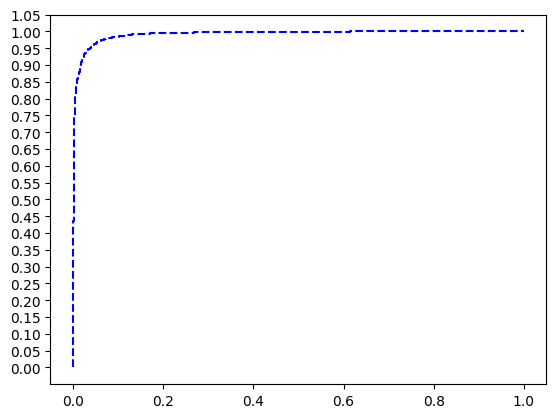

In [85]:
from matplotlib import pyplot as plt
plt.plot(fpr, tpr, linestyle='--', color='blue')
plt.yticks(np.arange(0, 1.1, step=0.05))

In [86]:
thresh

array([           inf, 9.99999225e-01, 9.99987960e-01, 9.99987066e-01,
       9.99976993e-01, 9.99975383e-01, 9.99959588e-01, 9.99958098e-01,
       9.99907792e-01, 9.99907613e-01, 9.99740064e-01, 9.99738753e-01,
       9.99695301e-01, 9.99692082e-01, 9.99143243e-01, 9.99142289e-01,
       9.99127388e-01, 9.99125421e-01, 9.98903155e-01, 9.98900712e-01,
       9.98556912e-01, 9.98556793e-01, 9.98237073e-01, 9.98235881e-01,
       9.96808350e-01, 9.96803880e-01, 9.96017218e-01, 9.96007323e-01,
       9.95914817e-01, 9.95912433e-01, 9.95354414e-01, 9.95352447e-01,
       9.95223939e-01, 9.95219409e-01, 9.93391097e-01, 9.93380904e-01,
       9.92625594e-01, 9.92618978e-01, 9.91563559e-01, 9.91556287e-01,
       9.91072059e-01, 9.91058588e-01, 9.88655210e-01, 9.88644361e-01,
       9.87608254e-01, 9.87602293e-01, 9.87579107e-01, 9.87536073e-01,
       9.78126466e-01, 9.78080332e-01, 9.61788952e-01, 9.61700499e-01,
       9.57057714e-01, 9.57017899e-01, 9.53714371e-01, 9.53704655e-01,
      

([<matplotlib.axis.YTick at 0x7f6f72e6acb0>,
 [Text(0, 0.0, '0.00'),
  Text(0, 0.05, '0.05'),
  Text(0, 0.1, '0.10'),
  Text(0, 0.15000000000000002, '0.15'),
  Text(0, 0.2, '0.20'),
  Text(0, 0.25, '0.25'),
  Text(0, 0.30000000000000004, '0.30'),
  Text(0, 0.35000000000000003, '0.35'),
  Text(0, 0.4, '0.40'),
  Text(0, 0.45, '0.45'),
  Text(0, 0.5, '0.50'),
  Text(0, 0.55, '0.55'),
  Text(0, 0.6000000000000001, '0.60'),
  Text(0, 0.65, '0.65'),
  Text(0, 0.7000000000000001, '0.70'),
  Text(0, 0.75, '0.75'),
  Text(0, 0.8, '0.80'),
  Text(0, 0.8500000000000001, '0.85'),
  Text(0, 0.9, '0.90'),
  Text(0, 0.9500000000000001, '0.95'),
  Text(0, 1.0, '1.00'),
  Text(0, 1.05, '1.05')])

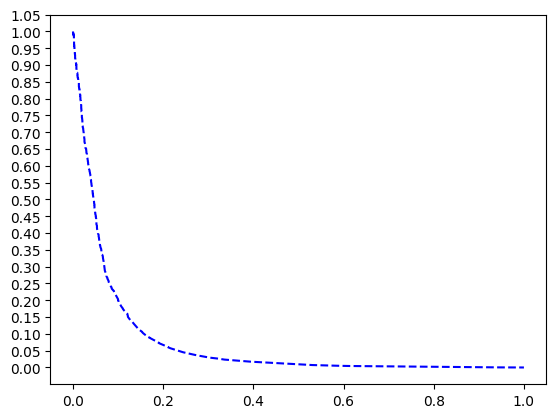

In [89]:
plt.plot(fpr, thresh, linestyle='--', color='blue')
plt.yticks(np.arange(0, 1.1, step=0.05))

In [90]:
tpr

array([0.00000000e+00, 3.04321363e-04, 1.82592818e-03, 2.43457091e-03,
       4.86914181e-03, 5.47778454e-03, 9.73828363e-03, 1.03469264e-02,
       2.09981741e-02, 2.16068168e-02, 5.26475959e-02, 5.32562386e-02,
       5.81253804e-02, 5.87340231e-02, 1.16250761e-01, 1.16859404e-01,
       1.18076689e-01, 1.18685332e-01, 1.41205113e-01, 1.41813755e-01,
       1.67376750e-01, 1.67985393e-01, 1.88374924e-01, 1.88983567e-01,
       2.58673159e-01, 2.59281802e-01, 2.92452830e-01, 2.92452830e-01,
       2.97321972e-01, 2.97930615e-01, 3.27145466e-01, 3.27754108e-01,
       3.32927572e-01, 3.32927572e-01, 3.91357273e-01, 3.91965916e-01,
       4.11138162e-01, 4.11138162e-01, 4.34570907e-01, 4.34570907e-01,
       4.43700548e-01, 4.44309191e-01, 4.87522824e-01, 4.87522824e-01,
       5.06695070e-01, 5.06695070e-01, 5.07608034e-01, 5.07608034e-01,
       6.09860012e-01, 6.09860012e-01, 7.02678028e-01, 7.02678028e-01,
       7.20328667e-01, 7.20328667e-01, 7.33110164e-01, 7.33718807e-01,
      